## Training Models

### Linear Regression -The 

A linear model predicts by computing a weighted sum of input
features plus  a constant called a bias term


$$ \hat{y} = \theta_0 + \theta_1x_1 + \theta_2x_2 + \cdots + \theta_nx_n = \theta^T x $$

Where:
         X = Inputs
         y = prediction 
         $ \theta $ = Feature

Vectorized Equation:
          $$ \hat{y} = \theta^T x $$


MSE of Linear REgression Model:
          $$ MSE(\theta) = \frac{1}{m}\sum_{i=1}^{m}(\theta^T x^{(i)} - y^{(i)})^2 $$


## The Normal Equation

To find the value of $ \theta $ that minimizes th cost function there is a closed form solution

 Normal Equation:\
            $ \hat{\theta} = (X^TX)^{-1}X^T $

          
          
$\hat{\theta} $   is the value of θ that minimizes the cost function. (Derivative of $ \theta $)

from :</br>
  $ X\theta= y $ </br>
  $ X^T X \theta = yX^T $</br>
  $ \theta = (XX^T)^-1yX^T$




In [20]:
import numpy as np

# Generate linear data: y = 4 + 3*x + noise

X=2* np.random.rand(100,1)
y= 4 + 3*X + np.random.randn(100,1)

# Add x0=1 column for bias
X_b = np.c_[np.ones((100, 1)), X]

# Solve directly
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
print(theta_best)
# array([[4.215],   <-- close to true θ0=4
#        [2.770]])  <-- close to true θ1=3, noise prevents exact recovery

[[4.21806408]
 [2.85579601]]


Sklearn uses SVD (pseudoinverse) instead — faster and handles singular matrices gracefully.

Pseudoinverse: \
             np.linalg.pinv(x)

## Gradient Descent

This is the iterative optimization starting from random $ \theta $.  repeatedly update it to reduce cost function 


![img](grad.png)

Concretely, you start by filling θ with random values (this is called random initializa‐
tion), and then you improve it gradually, taking one baby step at a time, each step
attempting to decrease the cost function (e.g., the MSE), until the algorithm converges
to a minimum

The size of the steps is determined by something called Learning Rate


GD update step:
       $ \theta \leftarrow \theta - \eta\,\nabla_\theta MSE(\theta) $

Partial derivative:  
     $ \frac{\partial}{\partial\theta_j}MSE(\theta) = \frac{2}{m}\sum_{i=1}^{m}(\theta^T x^{(i)} - y^{(i)})x_j^{(i)} $

Derivation:

from $$ MSE = \frac{1}{m}\sum_{i=1}^m(\theta^T x^i - y^i)^2 $$

let $$ e_i = \theta^T x^i - y^i $$ 

$$ MSE= \frac{1}{m}\sum_{i=1}^m(e_i)^2  $$


  Derivative of: $$ e_i^2   =    2e_1.\frac{\partial e_i}{\partial \theta _i} $$ 

  $$ \frac{\partial }{\partial \theta_j}MSE = \frac{1}{m}\sum_{i=1}^m{2e_i}\cdot{x_j^i}$$

  $$ =
  
  
  
  
  
   2 \times m \sum_{i=1}^m(\theta^Tx^i - y^i)\cdot x_j^i $$


   


Instead of computing these partial derivatives indivisually , we can compute them all in one go as in equation in the picture below to compute them all at once , the  Gradient vector is noted as $ \nabla_\theta MSE (\theta) $  is a collection of all the partial derivatives of the cost function for each of the model parameters 

![img](coll-grad.png)

after having the gradient vector which points uphill , just go in the opposite direction to go downhill. This means subtracting the vector from the $ \theta $ multiplied with the gradient vector

$ \theta^n = \theta - \eta\nabla_\theta MSE(\theta)$

#### Lets look at a quickly implementation of this algorithm

In [21]:
eta = 0.1  # learning rate
n_iterations = 1000
m = 100

theta = np.random.randn(2,1)

for iteration in range (n_iterations):
    gradients = 2/m * X_b.T.dot(X_b.dot(theta) - y)
    theta = theta - eta * gradients


To find a good learning rate, you can use grid search ,  However, you
may want to limit the number of iterations so that grid search can eliminate models
that take too long to converge.

In [22]:
print(theta)

[[4.21806408]
 [2.85579601]]


## Stochastic Gradient Descent

Batch Gradient Descent makes it slow whent the training set is very large  SGD picks a random instance in the training set at every step and computes the gradients based only on that single instance. makes it faster since it has very little data to manipulate every iteration


However this algorithm is much less regular than Batch Gradient Descent: instead of gently decreasing until it reaches the minimum, the cost function will bounce up and down , decreasing only on average. Never  settling around the minimum final parameters values are good , but not optimal

The randomness is good to escape from local optima, but bad because it means
that the algorithm can never settle at the minimum

One solution is to graddually decreasing the learning reate . The steps start out large then get smaller and smaller allowing the algorithm to settle at the global minimum. This process is called `` Simulated annealing `` 
There is a function that determines the learning rate at each iteration is known as learning schedule 

The following code implements SGD using learning schedule

In [23]:
import numpy as np

In [24]:
n_epochs = 50
t0 , t1 = 5, 50  ## learing schedule hpyerparameters

def learning_schedule(t):
    return t0 / (t + t1)

X_b=  np.c_[np.ones((100,1)), X]

theta = np.random.randn(2,1)  ## random initialization

for epoch in range(n_epochs):
    for i in range(m):
        random_index= np.random.randint(m)
        xi=X_b[random_index:random_index+1]
        yi=y[random_index:random_index+1]
        gradients = 2* xi.T.dot(xi.dot(theta) - yi)
        eta = learning_schedule(epoch * m + i )
        theta = theta - eta * gradients



In [25]:
theta

array([[4.15056936],
       [2.88166033]])

### Mini-batch Gradient Descent

computes gradients on small random sets called minibatches  .. it makes it possbile for perfomace boost from hardware optimization of matrix operations especially when using GPUs  reaches closer to the minimum than SGD

In [26]:
m = 100
X= 6*np.random.rand(m,1)-3

y= 0.5 * X**2 + X + 2 + np.random.randn(m,1)

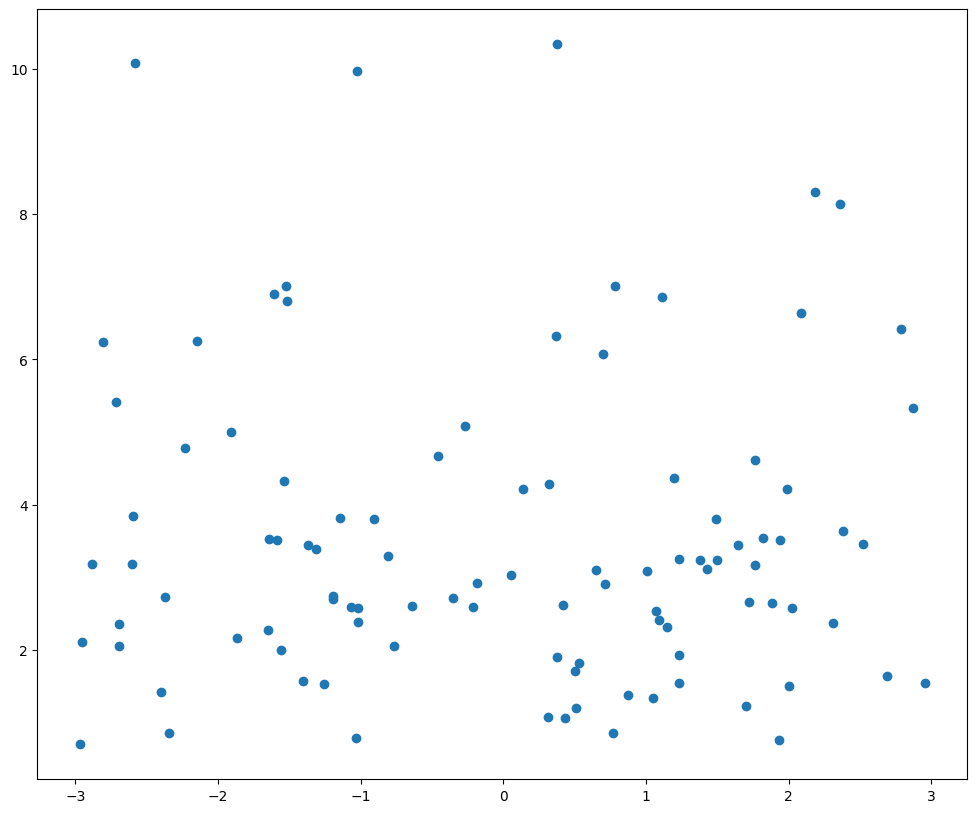

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,10))
plt.scatter (x,y)

### Polynomial Regression


from the data abouve  a straight line wont fit this data properly . So lets use scikit-Learn's polynomial features class to transform  our data add a square ($2^nd$ degree)

also Polynomial Regression is capable of finding relationships between features which is something plain Linear Regression model cant do

Applying higher degreee ploynomial to hthe model the model wiggles around tthe data to get as close but severly overfitting the training data . So how can you decided how complex the model should be .

Cross validation .. through this we get the estimate of the model's genralization perfomance Another way is to plot the `` Learning curves ``



## Regularized Linear Model

In a simple way regularization means constraining the weights of the model 

### Ridge Regression 
also known as Tikhonov regularization :</br>
a regularization term  $ \alpha \sum_{i=1}^n \theta_i^2 $ is added to the cost function causing the model algorith to fit the data but also keep the model weights as small as possible it is only added during training  hyper parmeter $ \alpha $ controls how much you want to regularize the 

Equation of Ridge Regression cost function

$ J(\theta) = MSE(\theta) + \alpha \frac{1}{2}\sum_{i=1}^n\theta_i^2 $

it is also important to scale the data before perfoming Ridge Regression , as it is sensitive to the scale of the input features . this is true of most regularized models

In [28]:
print(X)

[[-0.81717583]
 [ 2.66097233]
 [-1.03954759]
 [-2.22590179]
 [ 2.30878409]
 [-2.94732361]
 [ 0.05868509]
 [-2.42910422]
 [ 1.61036279]
 [-2.27747582]
 [ 1.99709771]
 [ 0.35934505]
 [-0.85181368]
 [-2.15826125]
 [ 1.84995932]
 [-0.88217645]
 [ 0.86574611]
 [-0.10935667]
 [ 1.10030272]
 [ 1.24783725]
 [ 0.57763624]
 [-0.25984288]
 [-1.743317  ]
 [ 0.99750066]
 [ 0.24456973]
 [ 0.23296734]
 [-2.94869698]
 [ 2.76532217]
 [-0.0355429 ]
 [ 0.7197722 ]
 [ 0.29782183]
 [-2.38693551]
 [-1.31662047]
 [ 2.88104682]
 [ 0.80670616]
 [-2.74193442]
 [ 0.77314865]
 [-0.71404235]
 [-2.83299541]
 [-2.0500486 ]
 [-2.32315911]
 [ 2.98955683]
 [ 0.41961106]
 [ 2.82140676]
 [-2.87712363]
 [-2.60617016]
 [-2.41527863]
 [-2.51168597]
 [ 2.22886933]
 [-2.31377556]
 [-0.44356966]
 [ 1.53389674]
 [ 0.38934033]
 [ 0.34468918]
 [-1.33961458]
 [-1.43766866]
 [-1.03625462]
 [ 1.12967184]
 [ 0.33067991]
 [-1.89583614]
 [-1.19093514]
 [ 2.23612875]
 [-2.44920983]
 [-0.86901323]
 [-1.90151043]
 [ 2.46611498]
 [ 1.18961

In [30]:
from sklearn.linear_model import Ridge

ridge_reg = Ridge(alpha=1, solver="cholesky")
ridge_reg.fit(X,y)

,alpha,1
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'cholesky'
,positive,False
,random_state,None


In [31]:
ridge_reg.predict([[1.5]])

array([4.72251844])

In [34]:
from sklearn.linear_model import SGDRegressor

In [36]:
sgd_reg=SGDRegressor(penalty="l2")
sgd_reg.fit(X,y.ravel())

,loss,'squared_error'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,random_state,None


The penalty parameters sets the type of regularization term to use  specififying "l2" indicates that you want to use SGD toadd a regularization term to the cost function equal to half the square of the l2 norm of the weight vector

In [38]:
sgd_reg.predict([[1.5]])

array([4.68869665])

## Lasso Regression
long form Least Absolute shrinkage and Selection operator Regression

Similar to Ridge  but is uses l1 norm of the weight vector instead of the half the square of the l2 norm

Equation : </br>

$ J(\theta) = MSE(\theta) + \alpha \sum_{i=1}^n |\theta_i|$

L1 tends to push some weights exactly to zero
it adds absolute values of some weights 

L2 add the squares of the weights
shrinks the weights towards zero but not exactly zero

## Elastic Net 

Elastic net is a mixture of both Ridge and Lasso regularization when r= 0 elastic net = Ridge and when r = 1 Elastic net = Lasso

$ J(\theta) = MSE(\theta) + r\alpha \sum_{i=1}^n |\theta_i| + \frac{1-r}{2}\alpha \sum_{i=1}^n (\theta_i)^2$

## Early Stopping 
Stopping as soon as the error reaches 

with Stochatic and Mini-batch Gradient Descent Curves are not so smooth making ti hard to know when  have reached the minimum
The solution is to stop only after the validation error has been the minimum for some time when confident that the model will no do any better

In [45]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures

In [50]:
poly_scaler = Pipeline ([
    ("poly_feature", PolynomialFeatures(degree=90,include_bias=False)),
    ("std_scaler", StandardScaler())
])

X_train_poly_scaled = poly_scaler.fit_transform(X)
X_val_poly_scaled = poly_scaler.transform(X)

sgd_reg = SGDRegressor(max_iter=1, tol=np.inf , warm_start=True, penalty=None , learning_rate='constant',eta0=0.0005)

minimum_val_error = float('inf')
best_epoch = None 
best_model = None
for epoch in range(1000):
    sgd_reg.fit(X_train_poly_scaled,y)
    y_val_predict = sgd_reg.predict(X_val_poly_scaled)
    if val_error < minimum_val_error:
        minimum_val_error = val_error
        best_epoch = epoch
        best_model = clone(sgd_reg)


InvalidParameterError: The 'tol' parameter of SGDRegressor must be a float in the range [0.0, inf) or None. Got inf instead.